In [1]:
display("text/html", "<style>.container { width:100% !important; }</style>")

# We want to play around and understand how to get the calibrations going on this new data

In [2]:
using DataFrames, CSV, Plots, LaTeXStrings, DelimitedFiles, GLM

In [3]:
Plots.theme(:dao)

In [4]:
include("/home/jamesh/GitHub/Ecological-Preferential-Attachment/diversity-simulator.jl")
using .dsim

In [5]:
pal = cgrad(:tol_muted);
cpal10 = [pal[i] for i in 0.0:1/46:1];

In [6]:
read_data = CSV.read("/home/jamesh/GitHub/Ecological-Preferential-Attachment/Data_csv/Grilli-crosssecdata__datatax.csv", DataFrame)
# first split on classification
gd1 = groupby(read_data, :classification);

In [7]:
gd1;

For each classification, split up on the sample.

In [8]:
gd_classes = []
for gd in gd1
    push!(gd_classes, groupby(gd, :sample_id))
end

Now, we only want to work with a simple system to start. `Oral` at index 2 is a good system that nicely follows Heaps' law.

In [9]:
data = gd_classes[2];

We need to get the size of each of these systems.

In [10]:
sizes = sum.([data[x][!,:count] for x in 1:length(data)]);
maximum(sizes)

130072.0

Let's choose the smallest of these systems as the initial condition.

In [11]:
argmin(sizes)

59

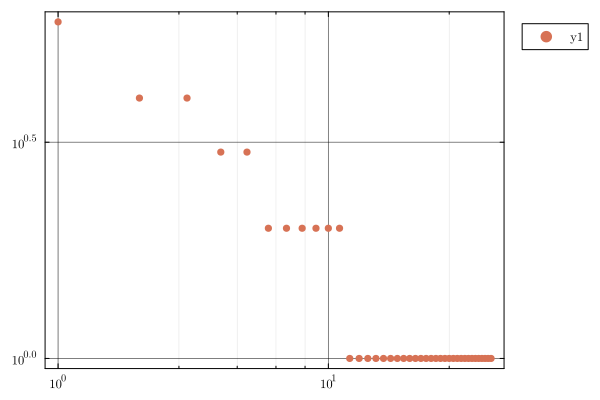

In [12]:
ic_sys = data[argmin(sizes)]
ic_sys = sort(ic_sys[!,:count],rev=true)
scatter(ic_sys, xaxis = :log, yaxis = :log)

Take the size of the largest system, and simulate ecosystems of that size from this initial condition.

In [13]:
guess_sim = dsim.create_cell(-0.1,0.93,10.0,convert(Int64,maximum(sizes)), ic_sys, :pdf)

1755-element Vector{Float64}:
 3801.0
 3339.0
 3227.0
 2981.0
 2747.0
 2650.0
 2461.0
 2427.0
 2120.0
 1999.0
 1967.0
 1841.0
 1689.0
    ⋮
    1.0
    1.0
    1.0
    1.0
    1.0
    1.0
    1.0
    1.0
    1.0
    1.0
    1.0
    1.0

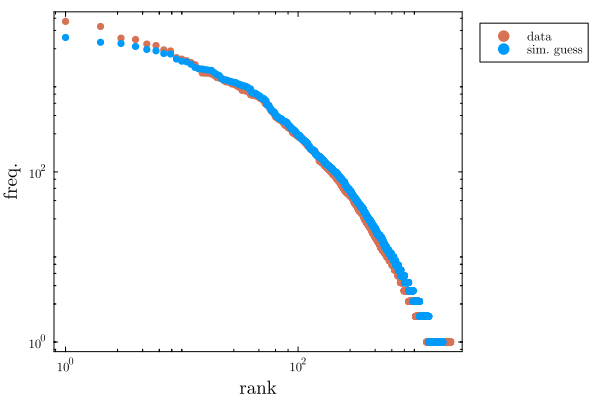

In [14]:
scatter(sort(data[argmax(sizes)][!,:count],rev=true), xaxis = :log, yaxis = :log, label = "data")
scatter!(guess_sim, label = "sim. guess", xlabel = "rank", ylabel = "freq.", grid = false, minorgrid = false)

Pretty quickly, we can get something that is bang on!

## Now, need to formalize this a little bit.

- Calculate $p_0$ from the diversity curve and initial condition.
- Set up a simple calibration procedure to go from the smallest to the largest ecosystem.
- Generalize this to do the top 10 ecosystems in terms of size. 

In [15]:
logxs = log10.(sum.([x[!,:count] for x in data]))
logys = log10.(length.([x[!,:count] for x in data]));

In [16]:
df = DataFrame(y = logys, x = logxs);

In [17]:
glm = lm(@formula(y ~ x), df)

StatsModels.TableRegressionModel{LinearModel{GLM.LmResp{Vector{Float64}}, GLM.DensePredChol{Float64, LinearAlgebra.CholeskyPivoted{Float64, Matrix{Float64}, Vector{Int64}}}}, Matrix{Float64}}

y ~ 1 + x

Coefficients:
────────────────────────────────────────────────────────────────────────
                Coef.  Std. Error      t  Pr(>|t|)  Lower 95%  Upper 95%
────────────────────────────────────────────────────────────────────────
(Intercept)  0.708404   0.0473157  14.97    <1e-25   0.614417   0.802391
x            0.53238    0.0111613  47.70    <1e-65   0.51021    0.554551
────────────────────────────────────────────────────────────────────────

In [18]:
a,b = coef(glm)

2-element Vector{Float64}:
 0.7084042943965811
 0.532380399267376

Following the SI of the PNAS paper...

In [19]:
θ = 2+1/(b-1);

In [20]:
ic_sys;

In [21]:
α = sum([k^θ for k in ic_sys])/(sum(ic_sys)^(1/(2-θ)))
p0 = α*a*b; 

This value of $p_0$ seems to be quite the underestimate. Especially so when the noise in the Heaps' law is expected to be high. Perhaps let's use ten times this value as an upper bound of $p_0$, and have the lower bound as $p_0$. No need to infer $p_0$ in log-space. 